<a href="https://colab.research.google.com/github/ThembaMapundu/MMA3001-Project/blob/main/notebooks/interpolation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
#Interpotation to see if values are close to the known values

# Methods:
# 1. Linear Interpolation
# 2. Cubic Spline Interpolation
# 3. PCHIP Interpolation

# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import CubicSpline
from scipy.interpolate import PchipInterpolator
from time import perf_counter

#  IMPORT CLEANED DATA FROM GITHUB
url = (f"https://raw.githubusercontent.com/ThembaMapundu/MMA3001-Project/main/SourceData/co2_clean.xlsx")

# Pandas is used to read the Excel file
data = pd.read_excel(url, engine="openpyxl")
print("Dataset imported successfully")
print("Total records:", len(data))
print("Columns:", data.columns.tolist())

# 3. DEFINE FUNCTIONS
# Function 1: Prepare sensor data
def prepare_sensor_data(data, sensor_id):
    """
    Extract and clean CO2 measurements for one sensor.

    Parameters
    ----------
    data : pandas.DataFrame
        Cleaned environmental dataset containing sensor_id,
        timestamp_utc and co2_ppm columns.

    sensor_id : int
        Sensor identifier to analyse.

    Returns
    -------
    time : numpy.ndarray
        Chronologically ordered timestamps in UTC.

    co2 : numpy.ndarray
        Valid CO2 concentrations in ppm.

    Raises
    ------
    ValueError
        If the sensor has insufficient valid measurements.
    """

    # Extract records for the selected sensor
    sensor_ids = pd.to_numeric(data["sensor_id"], errors="coerce")

    selected = data.loc[sensor_ids == sensor_id].copy()

    # Convert timestamps to UTC
    timestamps = pd.to_datetime(selected["timestamp_utc"], errors="coerce",utc=True)

    # Convert to NumPy datetime64
    time = ( timestamps.dt.tz_localize(None).to_numpy(dtype="datetime64[s]"))

    # Extract CO2 measurements
    co2 = pd.to_numeric(selected["co2_ppm"], errors="coerce").to_numpy(dtype=float)

    # Identify valid observations
    valid = ((~np.isnat(time)) & np.isfinite(co2)& (co2 > 0))
    time = time[valid]
    co2 = co2[valid]

    # Sort observations by timestamp
    order = np.argsort(time)
    time = time[order]
    co2 = co2[order]

    # Consolidate duplicate timestamps using the median
    unique_time, inverse = np.unique(time, return_inverse=True)

    co2 = np.array([np.median(co2[inverse == i])for i in range(len(unique_time)) ])

    time = unique_time

    if len(time) < 14:
        raise ValueError(
            "Insufficient measurements for interpolation."
        )

    return time, co2


# Function 2: Identify valid missing-data locations
def find_valid_gaps(time, gap_size, min_dt=8, max_dt=12):
    """
    Find locations suitable for artificial missing-data gaps.

    Parameters
    ----------
    time : numpy.ndarray
        Sorted measurement timestamps.

    gap_size : int
        Number of consecutive observations to hide.

    min_dt, max_dt : float
        Acceptable time intervals in minutes.

    Returns
    -------
    numpy.ndarray
        Candidate indices of the first hidden measurement.

    Notes
    -----
    The selected gap must have a known measurement on
    either side and approximately regular sampling.
    """

    if gap_size < 1:
        raise ValueError("Gap size must be positive.")

    # Calculate intervals in minutes
    dt = np.diff(time) / np.timedelta64(1, "m")

    regular = (dt >= min_dt) & (dt <= max_dt)

    valid_starts = []

    # Leave one known measurement before and after gap
    for start in range(1, len(time) - gap_size):

        # A gap of n points requires n+1 regular intervals
        if np.all(regular[start-1:start+gap_size]):
            valid_starts.append(start)

    return np.array(valid_starts, dtype=int)


# Function 3: Create artificial missing-data gap
def create_missing_gap(co2, start_index, gap_size):
    """
    Hide consecutive CO2 measurements for validation.

    Parameters
    ----------
    co2 : numpy.ndarray
        Original CO2 measurements in ppm.

    start_index : int
        Index of first measurement to hide.

    gap_size : int
        Number of measurements to remove.

    Returns
    -------
    observed : numpy.ndarray
        CO2 measurements with selected values set to NaN.

    missing_idx : numpy.ndarray
        Indices of hidden observations.

    true_values : numpy.ndarray
        Original hidden values retained for validation.
    """

    co2 = np.asarray(co2, dtype=float)

    if (gap_size < 1or start_index < 1 or start_index + gap_size >= len(co2)
    ):
        raise ValueError("Invalid missing-data gap.")

    missing_idx = np.arange(start_index,start_index + gap_size)

    # Preserve the original measurements
    true_values = co2[missing_idx].copy()

    # Create a separate dataset with missing values
    observed = co2.copy()
    observed[missing_idx] = np.nan

    return observed, missing_idx, true_values

# Function 4: Classify interpolation / extrapolation
def prediction_region(x_query, x_data):
    """
    Classify requested prediction locations.

    Parameters
    ----------
    x_query : array-like
        Numerical timestamps requiring predictions.

    x_data : array-like
        Known numerical timestamps.

    Returns
    -------
    str or numpy.ndarray
        'interpolation' or 'extrapolation'.
    """

    x_query = np.atleast_1d(x_query).astype(float)
    x_data = np.asarray(x_data, dtype=float)

    if (
        x_query.size == 0
        or x_data.size == 0
        or not np.all(np.isfinite(x_query))
        or not np.all(np.isfinite(x_data))
    ):
        raise ValueError("Invalid prediction timestamps.")

    labels = np.where(
        (x_query >= np.min(x_data))
        & (x_query <= np.max(x_data)),
        "interpolation",
        "extrapolation"
    )

    return labels[0] if labels.size == 1 else labels

# Function 5: Validate interpolation inputs
def validate_inputs(x_known, y_known, x_query):
    """
    Validate numerical interpolation inputs.

    All timestamps must use consistent numerical units.
    CO2 concentrations must be expressed in ppm.
    """

    x = np.asarray(x_known, dtype=float)
    y = np.asarray(y_known, dtype=float)
    xq = np.atleast_1d(x_query).astype(float)

    if x.ndim != 1 or y.ndim != 1 or xq.ndim != 1:
        raise ValueError("Inputs must be one-dimensional.")

    if len(x) != len(y) or len(x) < 2:
        raise ValueError("Invalid input array lengths.")

    if not all(np.all(np.isfinite(a)) for a in (x, y, xq)):
        raise ValueError("Inputs must be finite.")

    if np.any(np.diff(x) <= 0):
        raise ValueError("Known timestamps must increase.")

    if np.any(y <= 0):
        raise ValueError("CO2 measurements must be positive.")

    if np.any(xq < x[0]) or np.any(xq > x[-1]):
        raise ValueError("Extrapolation is not supported.")

    return x, y, xq

# Function 6: Linear interpolation
def linear_interpolation(x_known, y_known, x_query):
    """
    Reconstruct missing CO2 using linear interpolation.

    Parameters
    ----------
    x_known : array-like
        Known timestamps, expressed in elapsed minutes.

    y_known : array-like
        Known CO2 concentrations in ppm.

    x_query : array-like
        Timestamps where CO2 is missing.

    Returns
    -------
    numpy.ndarray
        Reconstructed CO2 concentrations in ppm.
    """

    x, y, xq = validate_inputs(
        x_known, y_known, x_query
    )

    return np.interp(xq, x, y)

# Function 7: Cubic spline interpolation
def cubic_spline_interpolation(x_known, y_known, x_query):
    """
    Reconstruct missing CO2 using natural cubic splines.

    Parameters
    ----------
    x_known : array-like
        Known timestamps in elapsed minutes.

    y_known : array-like
        Known CO2 concentrations in ppm.

    x_query : array-like
        Missing timestamps in elapsed minutes.

    Returns
    -------
    numpy.ndarray
        Reconstructed CO2 concentrations in ppm.
    """

    x, y, xq = validate_inputs(
        x_known, y_known, x_query
    )

    model = CubicSpline(
        x, y, bc_type="natural"
    )

    return model(xq)

# Function 8: PCHIP interpolation
def pchip_interpolation(x_known, y_known, x_query):
    """
    Reconstruct missing CO2 using PCHIP interpolation.

    Parameters
    ----------
    x_known : array-like
        Known timestamps in elapsed minutes.

    y_known : array-like
        Known CO2 concentrations in ppm.

    x_query : array-like
        Missing timestamps in elapsed minutes.

    Returns
    -------
    numpy.ndarray
        Reconstructed CO2 concentrations in ppm.
    """

    x, y, xq = validate_inputs(
        x_known, y_known, x_query
    )

    model = PchipInterpolator(x, y)

    return model(xq)

# Function 9: Calculate errors
def calculate_errors(y_true, y_pred):
    """
    Calculate interpolation reconstruction errors.

    Parameters
    ----------
    y_true : array-like
        Original hidden CO2 measurements in ppm.

    y_pred : array-like
        Reconstructed CO2 measurements in ppm.

    Returns
    -------
    mae : float
        Mean Absolute Error in ppm.

    rmse : float
        Root Mean Square Error in ppm.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if (
        y_true.shape != y_pred.shape
        or y_true.size == 0
        or not np.all(np.isfinite(y_true))
        or not np.all(np.isfinite(y_pred))
    ):
        raise ValueError("Invalid error calculation inputs.")

    errors = y_true - y_pred

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))

    return mae, rmse

# Function 10: Compare interpolation methods
def compare_methods(x_known, y_known, x_query, y_true):
    """
    Compare three interpolation methods on identical inputs.

    Parameters
    ----------
    x_known : array-like
        Available measurement times in minutes.

    y_known : array-like
        Available CO2 concentrations in ppm.

    x_query : array-like
        Hidden measurement times in minutes.

    y_true : array-like
        Original hidden CO2 values in ppm.

    Returns
    -------
    dict
        Estimated CO2 values, MAE, RMSE and runtime
        for each interpolation method.
    """

    methods = {
        "Linear": linear_interpolation,
        "Cubic Spline": cubic_spline_interpolation,
        "PCHIP": pchip_interpolation
    }

    results = {}

    for name, method in methods.items():

        start_timer = perf_counter()

        estimate = method(
            x_known, y_known, x_query
        )

        runtime = perf_counter() - start_timer

        mae, rmse = calculate_errors(
            y_true, estimate
        )

        results[name] = {
            "estimates": estimate,
            "MAE": mae,
            "RMSE": rmse,
            "runtime": runtime
        }

    return results




<>:171: SyntaxWarning: invalid decimal literal
<>:171: SyntaxWarning: invalid decimal literal
/tmp/ipykernel_4160/498655124.py:171: SyntaxWarning: invalid decimal literal
  if (gap_size < 1or start_index < 1 or start_index + gap_size >= len(co2)


Dataset imported successfully
Total records: 42843
Columns: ['sensor_id', 'timestamp_utc', 'co2_ppm']



SELECTED SENSOR
Sensor ID: 6012002000869
Measurements: 13800

Prediction region: ['interpolation' 'interpolation' 'interpolation']

INTERPOLATION COMPARISON

Method: Linear
Estimated CO2: [433.74 435.5  437.25]
MAE: 9.335 ppm
RMSE: 9.452 ppm
Runtime: 0.000100 s

Method: Cubic Spline
Estimated CO2: [437.45 440.53 441.09]
MAE: 7.705 ppm
RMSE: 8.080 ppm
Runtime: 0.000415 s

Method: PCHIP
Estimated CO2: [433.09 435.5  437.9 ]
MAE: 9.773 ppm
RMSE: 9.864 ppm
Runtime: 0.000337 s


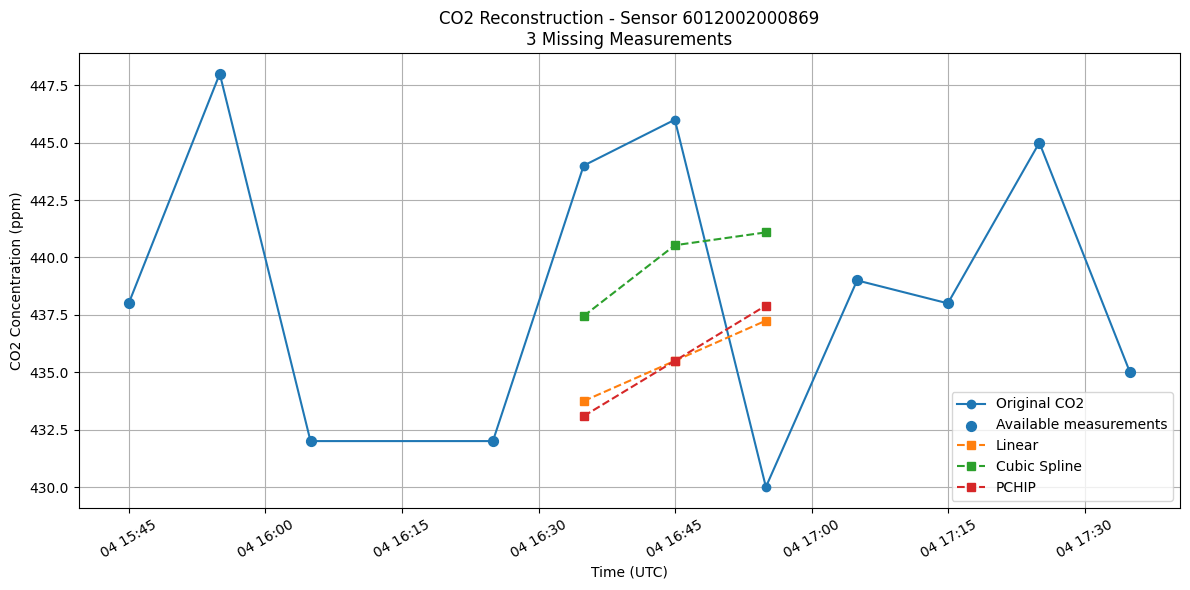

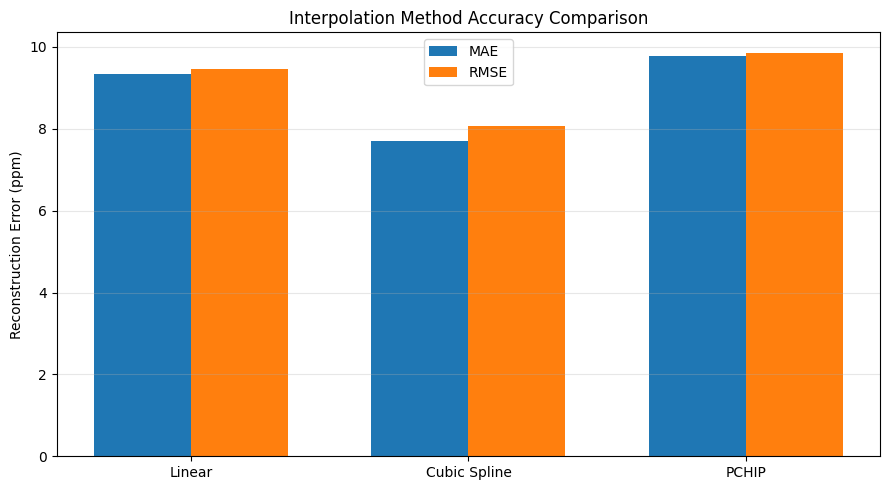


BEST METHOD FOR THIS TEST GAP
Method: Cubic Spline
RMSE: 8.08 ppm

Note: This is only one test gap.
Repeated experiments are required before selecting a final method.


In [11]:


# RUN INTERPOLATION EXPERIMENT

# Use the sensor selected in Notebook 02
sensor_id = 6012002000869

time, co2 = prepare_sensor_data(data, sensor_id)

print("\nSELECTED SENSOR")
print("Sensor ID:", sensor_id)
print("Measurements:", len(co2))


# Select an artificial gap
gap_size = 3

candidate_starts = find_valid_gaps(
    time, gap_size
)

if len(candidate_starts) == 0:
    raise ValueError("No suitable gaps found.")

# Use first eligible gap for demonstration
start_index = int(candidate_starts[0])

observed, missing_idx, true_values = create_missing_gap(co2, start_index, gap_size)

# Convert timestamps to elapsed minutes
x = ((time - time[0]) / np.timedelta64(1, "m")).astype(float)

# Select a local window around the missing gap
# Use up to four available measurements on each side.
# This avoids fitting splines across the entire history.
local_left = max(0, start_index - 4)
local_right = min(len(co2),start_index + gap_size + 4)

local_idx = np.arange(local_left, local_right)

# Only available observations may be used for fitting
local_known_idx = local_idx[np.isfinite(observed[local_idx])]

# Reject the window if its outer sampling intervals
# are irregular; use more suitable gaps in later trials.
local_dt = np.diff(time[local_idx]) / np.timedelta64(1, "m")

if not np.all((local_dt >= 8) & (local_dt <= 12)):
    print(
        "Warning: Some intervals in the wider local "
        "window are irregular. Review this test window."
    )

x_known = x[local_known_idx]
y_known = observed[local_known_idx]

x_query = x[missing_idx]

# Confirm this is interpolation, not extrapolation
region = prediction_region(x_query, x_known)

print("\nPrediction region:", region)

# Compare all three methods


results = compare_methods(x_known,y_known,x_query,true_values)

# DISPLAY NUMERICAL RESULTS
print("\nINTERPOLATION COMPARISON")

for name, result in results.items():

    print(f"\nMethod: {name}")
    print("Estimated CO2:",np.round(result["estimates"], 2))
    print(f"MAE: {result['MAE']:.3f} ppm")
    print(f"RMSE: {result['RMSE']:.3f} ppm")
    print(f"Runtime: {result['runtime']:.6f} s")

# PLOT ORIGINAL AND RECONSTRUCTED MEASUREMENTS

plt.figure(figsize=(12, 6))

# Original measured CO2
plt.plot(time[local_idx],co2[local_idx],"o-",label="Original CO2",linewidth=1.5)

# Available measurements after hiding selected points
plt.scatter(time[local_known_idx],observed[local_known_idx],label="Available measurements",s=50,zorder=4)

# Plot estimated missing measurements for each method
for name, result in results.items():
    plt.plot(time[missing_idx],result["estimates"],marker="s",linestyle="--",label=name)

plt.xlabel("Time (UTC)")
plt.ylabel("CO2 Concentration (ppm)")
plt.title(f"CO2 Reconstruction - Sensor {sensor_id}\n"f"{gap_size} Missing Measurements")

plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# PLOT METHOD COMPARISON

method_names = list(results.keys())

rmse_values = [results[name]["RMSE"]for name in method_names]

mae_values = [results[name]["MAE"]for name in method_names]

positions = np.arange(len(method_names))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(positions - width/2,mae_values,width,label="MAE")

plt.bar(positions + width/2,rmse_values,width,label="RMSE")

plt.xticks(positions, method_names)
plt.ylabel("Reconstruction Error (ppm)")
plt.title("Interpolation Method Accuracy Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# DISPLAY BEST METHOD FOR THIS DEMONSTRATION
best_method = min(results,key=lambda name: results[name]["RMSE"])

print("\nBEST METHOD FOR THIS TEST GAP")
print("Method:", best_method)
print("RMSE:",round(results[best_method]["RMSE"], 3),"ppm")
